# Hospital readmission data preprocessing and exploratory analysis

**GenoMining — Section 3 submission notebook.** One row is a historical hospital encounter involving diabetes. We explore recorded early readmission and prepare inputs for a later prediction study at discharge. This notebook covers EDA and preprocessing; it makes no classifier-performance or clinical-deployment claims.

**Run:** open this folder in VS Code, select the Python environment installed from `requirements.txt`, then **Restart Kernel and Run All**. All input data are local. Every run recalculates the results and overwrites generated files inside `outputs/`; no downloaded data, repository modules, saved transformers or previous results are required. Package installation needs internet access unless the packages are already available.

**Reading order:** data overview and quality → patient partitions → development EDA → learned cleaning and selection → outlier screening → PCA → verification. Four essential figures are generated by the code and displayed here; separate PNGs are available for the report. `Report.pdf` beside this notebook contains the annotated report and code lookup notes. Review and finalize that report with your team before submission.

Diagnostic tables and run audits remain available as the `evidence_tables` and `audits` dictionaries after execution. Only the four essential figures and prepared matrix with its row/column labels are exported, keeping the submission compact.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.metadata
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from scipy import sparse
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted

# The notebook lives beside config.json and data/. No search outside this folder.
ROOT = Path.cwd().resolve()
assert (ROOT / 'data/diabetic_data.csv').is_file(), 'Open the submission folder as the notebook working directory.'
OUT = ROOT / 'outputs'
settings = json.loads((ROOT / 'config.json').read_text(encoding='utf-8'))
seed, dpi = settings['seed'], settings['figure_dpi']
start = perf_counter()
NUMERIC = ['time_in_hospital', 'num_lab_procedures', 'num_procedures',
           'num_medications', 'number_outpatient', 'number_emergency',
           'number_inpatient', 'number_diagnoses']
IDS = ['encounter_id', 'patient_nbr']
TARGET = 'readmitted'
EXCLUDED_DISCHARGES = {11, 13, 14, 19, 20, 21}
DATA_PAGE = 'https://doi.org/10.24432/C5230J'
BLUE, ORANGE = '#246b83', '#c26b32'
LABELS = dict(zip(NUMERIC, ['Length of stay (days)', 'Laboratory procedures', 'Other procedures',
    'Medications', 'Prior outpatient visits', 'Prior emergency visits', 'Prior inpatient visits', 'Diagnoses']))
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

def config():
    return settings.copy()

def environment():
    packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']
    return {'python': platform.python_version(), 'platform': platform.platform(),
            'packages': {name: importlib.metadata.version(name) for name in packages}}

def sha256(file):
    return hashlib.sha256(Path(file).read_bytes()).hexdigest()

display(pd.Series(environment()['packages'], name='Installed version').to_frame())

,Installed version
numpy,2.2.6
pandas,2.3.3
scipy,1.16.2
scikit-learn,1.7.2
matplotlib,3.10.7
nbformat,5.10.4
nbclient,0.10.2
ipykernel,6.30.1


In [2]:
evidence_tables, audits = {}, {}

def output(relative):
    """Resolve generated output paths inside this submission folder."""
    target = OUT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    return target


def record_audit(relative, value):
    """Keep run audits inside the notebook instead of exporting duplicate JSON files."""
    audits[relative.removesuffix(".json")] = value


def record_table(frame, name, index=False):
    """Keep diagnostic tables in memory; export only the prepared matrix column labels."""
    evidence_tables[name] = frame.copy()
    if name == "encoded_feature_names":
        frame.to_csv(output("prepared/encoded_feature_names.csv"), index=index)


def save_figure(fig, name, dpi):
    fig.savefig(output('figures/' + name + '.png'), dpi=dpi, bbox_inches='tight')
    display(Image(filename=str(output('figures/' + name + '.png'))))
    plt.close(fig)


def iqr_screen(values):
    """Flag observations outside 1.5 IQR fences for review, including explicit zero-IQR diagnostics."""
    rows, flags = [], pd.DataFrame(index=values.index)
    for name in values:
        q1, q3 = values[name].quantile([.25, .75])
        spread = q3 - q1
        low, high = q1 - 1.5 * spread, q3 + 1.5 * spread
        flag = values[name].lt(low) | values[name].gt(high)
        flags[name] = flag
        rows.append({'feature': name, 'q1': q1, 'q3': q3, 'iqr': spread,
                     'lower_fence': low, 'upper_fence': high, 'zero_iqr': bool(spread == 0),
                     'flagged_encounters': int(flag.sum()), 'flagged_percent': float(flag.mean() * 100)})
    return pd.DataFrame(rows), flags


def matrix_details(matrix):
    nnz = matrix.nnz if sparse.issparse(matrix) else np.count_nonzero(matrix)
    return {'rows': int(matrix.shape[0]), 'columns': int(matrix.shape[1]),
            'density': float(nnz / (matrix.shape[0] * matrix.shape[1])),
            'nonfinite_values': int((~np.isfinite(matrix.data if sparse.issparse(matrix) else matrix)).sum())}

## 1 Load data and inspect structure

Source: [UCI Diabetes 130 US Hospitals for Years 1999–2008](https://doi.org/10.24432/C5230J), CC BY 4.0. The included CSV is checked against its recorded SHA-256 hash. `?` is missing; laboratory `None` means **test not performed**, and medication `No` is a valid category. The release contains 101,766 encounters from 71,518 patients, with 47 candidate inputs, two identifiers and one outcome. Integer-valued admission/discharge codes are nominal categories, not quantities. See `data/IDS_mapping.csv` for their meanings.

In [3]:
raw_file = ROOT / 'data/diabetic_data.csv'
source_hash = sha256(raw_file)
assert source_hash == '0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97', 'Raw dataset has changed.'
raw = pd.read_csv(raw_file, keep_default_na=False, na_values=['?'], low_memory=False)
assert raw.shape == (101766, 50)
display(pd.Series({'encounters': len(raw), 'patients': raw.patient_nbr.nunique(),
                   'columns': raw.shape[1], 'candidate_inputs': raw.shape[1]-3}, name='Raw overview').to_frame())
display(raw.head())
overview = pd.DataFrame({'column': raw.columns, 'pandas_dtype': raw.dtypes.astype(str).values,
                        'distinct_including_missing': raw.nunique(dropna=False).values,
                        'missing_cells': raw.isna().sum().values})
record_table(overview, 'raw_column_overview')
display(overview)

,Raw overview
encounters,101766
patients,71518
columns,50
candidate_inputs,47


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,column,pandas_dtype,distinct_including_missing,missing_cells
0,encounter_id,int64,101766,0
1,patient_nbr,int64,71518,0
2,race,object,6,2273
3,gender,object,3,0
4,age,object,10,0
5,weight,object,10,98569
6,admission_type_id,int64,8,0
7,discharge_disposition_id,int64,26,0
8,admission_source_id,int64,17,0
9,time_in_hospital,int64,14,0


In [4]:
def dictionary(raw):
    definitions = {
        'encounter_id': 'Unique encounter ID; audit/join only, never a model input.',
        'patient_nbr': 'Patient grouping ID; used to prevent split overlap, never a model input.',
        'readmitted': 'Recorded readmission: <30 positive; >30 and NO negative.',
        'race': 'Recorded race category; missing values remain missing.',
        'gender': 'Recorded gender category; Unknown/Invalid retained as a category.',
        'age': 'Age in ten-year bands; categorical, not exact age.',
        'weight': 'Weight band; subject to training-only high-missingness exclusion.',
        'admission_type_id': 'Categorical admission type; see IDS_mapping.csv.',
        'discharge_disposition_id': 'Categorical discharge destination; used for cohort exclusions.',
        'admission_source_id': 'Categorical admission source; see IDS_mapping.csv.',
        'time_in_hospital': 'Length of the completed hospital stay in days.',
        'payer_code': 'Payer category; missingness retained as an explicit category.',
        'medical_specialty': 'Admitting physician specialty category.',
        'num_lab_procedures': 'Number of laboratory tests performed during this encounter.',
        'num_procedures': 'Number of non-laboratory procedures during this encounter.',
        'num_medications': 'Number of distinct generic medications during the encounter.',
        'number_outpatient': 'Outpatient encounters in the preceding year.',
        'number_emergency': 'Emergency encounters in the preceding year.',
        'number_inpatient': 'Inpatient encounters in the preceding year.',
        'diag_1': 'Primary ICD-9 diagnosis; deterministically grouped for modeling.',
        'diag_2': 'Secondary ICD-9 diagnosis; deterministically grouped for modeling.',
        'diag_3': 'Additional ICD-9 diagnosis; deterministically grouped for modeling.',
        'number_diagnoses': 'Number of diagnoses entered into the encounter record.',
        'max_glu_serum': 'Glucose test category; None means not measured, NOT missing.',
        'A1Cresult': 'HbA1c category; None means not measured, NOT missing.',
        'change': 'Whether a diabetes medication changed during the encounter.',
        'diabetesMed': 'Whether a diabetes medication was prescribed.'}
    rows = []
    for name in raw:
        role = 'identifier' if name in IDS else ('target' if name == TARGET else 'candidate input')
        rows.append({'column': name, 'role': role,
                     'type': 'identifier' if name in IDS else ('integer' if name in NUMERIC else 'categorical'),
                     'description': definitions.get(name, 'Medication status: No, Steady, Up, or Down; No is a valid category.'),
                     'missing_token': '?', 'source': DATA_PAGE})
    return pd.DataFrame(rows)

record_table(dictionary(raw), 'data_dictionary')

## 2 Data quality checks and notes

Check both **exact duplicate rows** and **duplicate encounter IDs**. Repeated patient IDs are expected because a patient may have several encounters; they are not duplicate admissions to delete. Missing values are described separately from valid `None` categories. Nonnegative, finite numerical values are basic plausibility checks, not a clinical validation of every extreme value. Raw-data checks establish source quality; outcome relationships and learned decisions below use development patients only.

In [5]:
quality_audit = {
    'exact_duplicate_rows': int(raw.duplicated().sum()),
    'duplicate_encounter_ids': int(raw.encounter_id.duplicated().sum()),
    'rows_after_first_encounter_per_patient': int(raw.patient_nbr.duplicated().sum()),
    'negative_numeric_cells': int((raw[NUMERIC] < 0).sum().sum()),
    'nonfinite_observed_numeric_cells': int((~np.isfinite(raw[NUMERIC].to_numpy(dtype=float)) & raw[NUMERIC].notna().to_numpy()).sum()),
    'numeric_missing_cells': int(raw[NUMERIC].isna().sum().sum()),
    'missing_identifier_cells': int(raw[IDS].isna().sum().sum()),
    'noninteger_numeric_cells': int(((raw[NUMERIC] % 1 != 0) & raw[NUMERIC].notna()).sum().sum()),
    'stays_outside_source_range_1_to_14': int((~raw.time_in_hospital.between(1, 14)).sum()),
    'A1C_None_preserved': int(raw.A1Cresult.eq('None').sum()),
    'max_glu_None_preserved': int(raw.max_glu_serum.eq('None').sum()),
    'csv_sha256': source_hash,
}
assert quality_audit['exact_duplicate_rows'] == quality_audit['duplicate_encounter_ids'] == 0
assert quality_audit['negative_numeric_cells'] == quality_audit['nonfinite_observed_numeric_cells'] == 0
assert quality_audit['missing_identifier_cells'] == quality_audit['noninteger_numeric_cells'] == quality_audit['stays_outside_source_range_1_to_14'] == 0
assert raw.patient_nbr.nunique() == 71518 and set(raw.readmitted.unique()) == {'<30', '>30', 'NO'}
record_audit('quality_audit.json', quality_audit)
display(pd.Series(quality_audit, name='Result').to_frame())
raw_missing = pd.DataFrame({'feature': raw.columns, 'missing_count': raw.isna().sum().values,
                           'missing_percent': 100*raw.isna().mean().values}).sort_values('missing_percent', ascending=False)
record_table(raw_missing, 'raw_missingness')
display(raw_missing.loc[raw_missing.missing_count.gt(0)])
display(Markdown('**Quality note:** no exact duplicate rows or duplicate encounter IDs were found. '
                 'Repeated patient rows are retained and grouped in the split. Missingness is concentrated in weight, '
                 'specialty and payer fields; only development missingness determines cleaning decisions.'))

# Verified against the included source mapping; these states are not literal ? missingness.
unknown_codes = {'admission_type_id': [5, 6, 8],
                 'admission_source_id': [9, 15, 17, 20, 21],
                 'discharge_disposition_id': [18, 25, 26]}
unknown_summary = pd.DataFrame([{'feature': name, 'unknown_codes': ', '.join(map(str, codes)),
    'encounters': int(raw[name].isin(codes).sum()), 'percent': float(raw[name].isin(codes).mean()*100)}
    for name, codes in unknown_codes.items()])
record_table(unknown_summary, 'coded_unknowns')
display(unknown_summary)
print('Unknown/Invalid gender entries:', int(raw.gender.eq('Unknown/Invalid').sum()))
display(Markdown('**Coded-unknown note:** unavailable, NULL, unmapped and invalid codes are kept as '
                 'distinct nominal categories. They represent incomplete information but are not counted as literal ? '
                 'missing cells. The source mapping defines them; no numeric distance is inferred.'))

,Result
exact_duplicate_rows,0
duplicate_encounter_ids,0
rows_after_first_encounter_per_patient,30248
negative_numeric_cells,0
nonfinite_observed_numeric_cells,0
numeric_missing_cells,0
missing_identifier_cells,0
noninteger_numeric_cells,0
stays_outside_source_range_1_to_14,0
A1C_None_preserved,84748


,feature,missing_count,missing_percent
5,weight,98569,96.858479
11,medical_specialty,49949,49.082208
10,payer_code,40256,39.557416
2,race,2273,2.233555
20,diag_3,1423,1.398306
19,diag_2,358,0.351787
18,diag_1,21,0.020636


**Quality note:** no exact duplicate rows or duplicate encounter IDs were found. Repeated patient rows are retained and grouped in the split. Missingness is concentrated in weight, specialty and payer fields; only development missingness determines cleaning decisions.

,feature,unknown_codes,encounters,percent
0,admission_type_id,"5, 6, 8",10396,10.215593
1,admission_source_id,"9, 15, 17, 20, 21",7067,6.944363
2,discharge_disposition_id,"18, 25, 26",4680,4.598785


Unknown/Invalid gender entries: 3


**Coded-unknown note:** unavailable, NULL, unmapped and invalid codes are kept as distinct nominal categories. They represent incomplete information but are not counted as literal ? missing cells. The source mapping defines them; no numeric distance is inferred.

## 3 Define the cohort and protect held-out patients

Exclude encounters with death/hospice discharge codes 11, 13, 14, 19, 20 and 21. The target is recorded `<30` readmission (1) versus `>30`/`NO` (0). `NO` does not verify that a patient was never readmitted elsewhere. This is an **at-discharge** prediction setting because completed-stay variables are available then.

Five approximately stratified patient groups use seed 459: three development folds, one reserved calibration fold and one reserved test fold. The target is used only to construct the stratified partition; held-out outcomes are not used for exploratory associations or fitting. Dates and hospital identifiers needed for chronological/external-hospital validation are absent. This section preserves future evaluation partitions without evaluating a classifier.

In [6]:
def eligible_cohort(raw):
    if raw['encounter_id'].duplicated().any():
        raise ValueError('Duplicate encounter IDs; investigate source rather than silently drop rows.')
    if not set(raw[TARGET].unique()) <= {'<30', '>30', 'NO'}:
        raise ValueError('Unexpected readmission label.')
    cohort = raw.loc[~raw['discharge_disposition_id'].isin(EXCLUDED_DISCHARGES)].copy()
    cohort['target'] = cohort[TARGET].eq('<30').astype('int8')
    return cohort.reset_index(drop=True)


def assign_splits(frame, seed):
    # Five grouped, approximately stratified folds; three development, one calibration, one test.
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    assignments = np.full(len(frame), 'development', dtype=object)
    folds = np.full(len(frame), -1, dtype=int)
    for fold, (_, index) in enumerate(splitter.split(frame, frame['target'], frame['patient_nbr'])):
        folds[index] = fold
        if fold == 3:
            assignments[index] = 'calibration'
        elif fold == 4:
            assignments[index] = 'test'
    result = frame[IDS].copy()
    result['split'] = assignments
    result['partition_fold'] = folds
    if result.groupby('patient_nbr')['split'].nunique().max() != 1:
        raise AssertionError('Patient leakage in split assignment.')
    if (folds < 0).any():
        raise AssertionError('An encounter was not assigned.')
    return result


def xy(frame):
    return frame.drop(columns=IDS + [TARGET, 'target', 'split', 'partition_fold']), frame['target']

cohort = eligible_cohort(raw)
splits = assign_splits(cohort, seed)
cohort = cohort.merge(splits, on=IDS, validate='one_to_one')
record_table(splits, 'patient_partitions')

def load_cohort(split=None):
    """Access the in-memory cohort; no external file or repository is involved."""
    return cohort.copy() if split is None else cohort.loc[cohort.split.eq(split)].reset_index(drop=True)

dev = load_cohort('development')
X, y = xy(dev)
assert cohort.groupby('patient_nbr')['split'].nunique().max() == 1
assert len(dev) == 59670
data_audit = {'raw_encounters': len(raw), 'raw_patients': int(raw.patient_nbr.nunique()),
              'candidate_features': len(raw.columns)-3, 'excluded_discharge_codes': sorted(EXCLUDED_DISCHARGES),
              'excluded_encounters': len(raw)-len(cohort), 'eligible_encounters': len(cohort),
              'eligible_patients': int(cohort.patient_nbr.nunique()), 'patient_overlap': 0,
              'positive_encounters': int(cohort.target.sum()), 'positive_rate': float(cohort.target.mean()),
              'source_doi': '10.24432/C5230J', 'csv_sha256': source_hash,
              'note': 'Encounter-level counts. None laboratory values are retained.'}
record_audit('data_audit.json', data_audit)
display(cohort.groupby('split').agg(encounters=('encounter_id', 'size'), patients=('patient_nbr', 'nunique')))
display(Markdown(f'**Analysis population:** {len(dev):,} development encounters from '
                 f'{dev.patient_nbr.nunique():,} patients. All figures and learned transformations below use this population.'))

,encounters,patients
split,,
calibration,19746,14025
development,59670,41960
test,19927,14005


**Analysis population:** 59,670 development encounters from 41,960 patients. All figures and learned transformations below use this population.

## 4 Development distributions and relationships

These tables and three figures examine class balance, missingness, skewed count distributions and numeric associations. Spearman correlation is appropriate for rank relationships among skewed counts. Counts accompany categorical rates; these are descriptive associations, not causal effects. Histograms show all observations with a log **count axis**. Boxplots use 5th–95th percentile whiskers and hide outside points for readability; no records are deleted.

In [7]:
# EDA uses development encounters only. Full-cohort counts describe construction, not associations.
missing = pd.DataFrame({'feature': X.columns, 'missing_count': X.isna().sum().values,
                        'missing_percent': X.isna().mean().values * 100})
missing = missing.sort_values('missing_percent', ascending=False, kind='stable')
record_table(missing, 'missingness')
numeric = dev[NUMERIC].describe(percentiles=[.01, .25, .5, .75, .99]).T
numeric['zero_percent'] = dev[NUMERIC].eq(0).mean() * 100
numeric['skewness'] = dev[NUMERIC].skew()
record_table(numeric.rename_axis('feature').reset_index(), 'numeric_summary')
groups = dev.groupby('split').agg(encounters=('target', 'size'), patients=('patient_nbr', 'nunique'),
                                  early_readmissions=('target', 'sum'), positive_rate=('target', 'mean'))
record_table(groups.reset_index(), 'analysis_population')
split_sizes = cohort.groupby('split').agg(encounters=('encounter_id', 'size'), patients=('patient_nbr', 'nunique'))
record_table(split_sizes.reset_index(), 'split_sizes')
correlations = dev[NUMERIC].corr(method='spearman')
record_table(correlations.rename_axis('feature').reset_index(), 'spearman_correlations')
pairs = pd.DataFrame([{'feature_a': a, 'feature_b': b, 'spearman_rho': float(correlations.loc[a, b])}
                      for i, a in enumerate(NUMERIC) for b in NUMERIC[i+1:]])
pairs['absolute_rho'] = pairs.spearman_rho.abs()
pairs = pairs.sort_values('absolute_rho', ascending=False)
record_table(pairs, 'correlation_pairs')
categories = []
for name in ['age', 'A1Cresult', 'discharge_disposition_id']:
    part = dev.groupby(name, dropna=False).agg(encounters=('target', 'size'), early_readmissions=('target', 'sum'),
                                              observed_rate=('target', 'mean')).reset_index().rename(columns={name: 'category'})
    part.insert(0, 'feature', name)
    categories.append(part)
record_table(pd.concat(categories, ignore_index=True), 'categorical_associations')
lab_states = []
for name in ['A1Cresult', 'max_glu_serum']:
    for value, count in X[name].fillna('Missing').value_counts().items():
        lab_states.append({'feature': name, 'category': value, 'encounters': int(count), 'percent': float(count / len(dev) * 100)})
record_table(pd.DataFrame(lab_states), 'laboratory_categories')


display(numeric)
display(pd.concat(categories, ignore_index=True))

,count,mean,std,min,1%,25%,50%,75%,99%,max,zero_percent,skewness
time_in_hospital,59670.0,4.364454,2.952804,1.0,1.0,2.0,4.0,6.0,13.0,14.0,0.000000,1.148739
num_lab_procedures,59670.0,42.866583,19.568948,1.0,1.0,31.0,44.0,57.0,84.0,132.0,0.000000,-0.242283
num_procedures,59670.0,1.329160,1.702160,0.0,0.0,0.0,1.0,2.0,6.0,6.0,46.150494,1.330644
num_medications,59670.0,15.968762,8.080817,1.0,3.0,10.0,15.0,20.0,43.0,79.0,0.000000,1.348824
number_outpatient,59670.0,0.365913,1.251955,0.0,0.0,0.0,0.0,0.0,5.0,40.0,83.623261,8.959298
number_emergency,59670.0,0.204961,1.031906,0.0,0.0,0.0,0.0,0.0,3.0,76.0,88.756494,25.366605
number_inpatient,59670.0,0.637205,1.277435,0.0,0.0,0.0,0.0,1.0,6.0,21.0,66.597955,3.630713
number_diagnoses,59670.0,7.411111,1.936090,1.0,2.0,6.0,8.0,9.0,9.0,16.0,0.000000,-0.862448


,feature,category,encounters,early_readmissions,observed_rate
0,age,[0-10),95,3,0.031579
1,age,[10-20),408,22,0.053922
2,age,[20-30),980,136,0.138776
3,age,[30-40),2282,263,0.115250
4,age,[40-50),5884,645,0.109619
5,age,[50-60),10344,1048,0.101315
6,age,[60-70),13256,1481,0.111723
7,age,[70-80),15099,1841,0.121929
8,age,[80-90),9783,1243,0.127057
9,age,[90-100),1539,172,0.111761


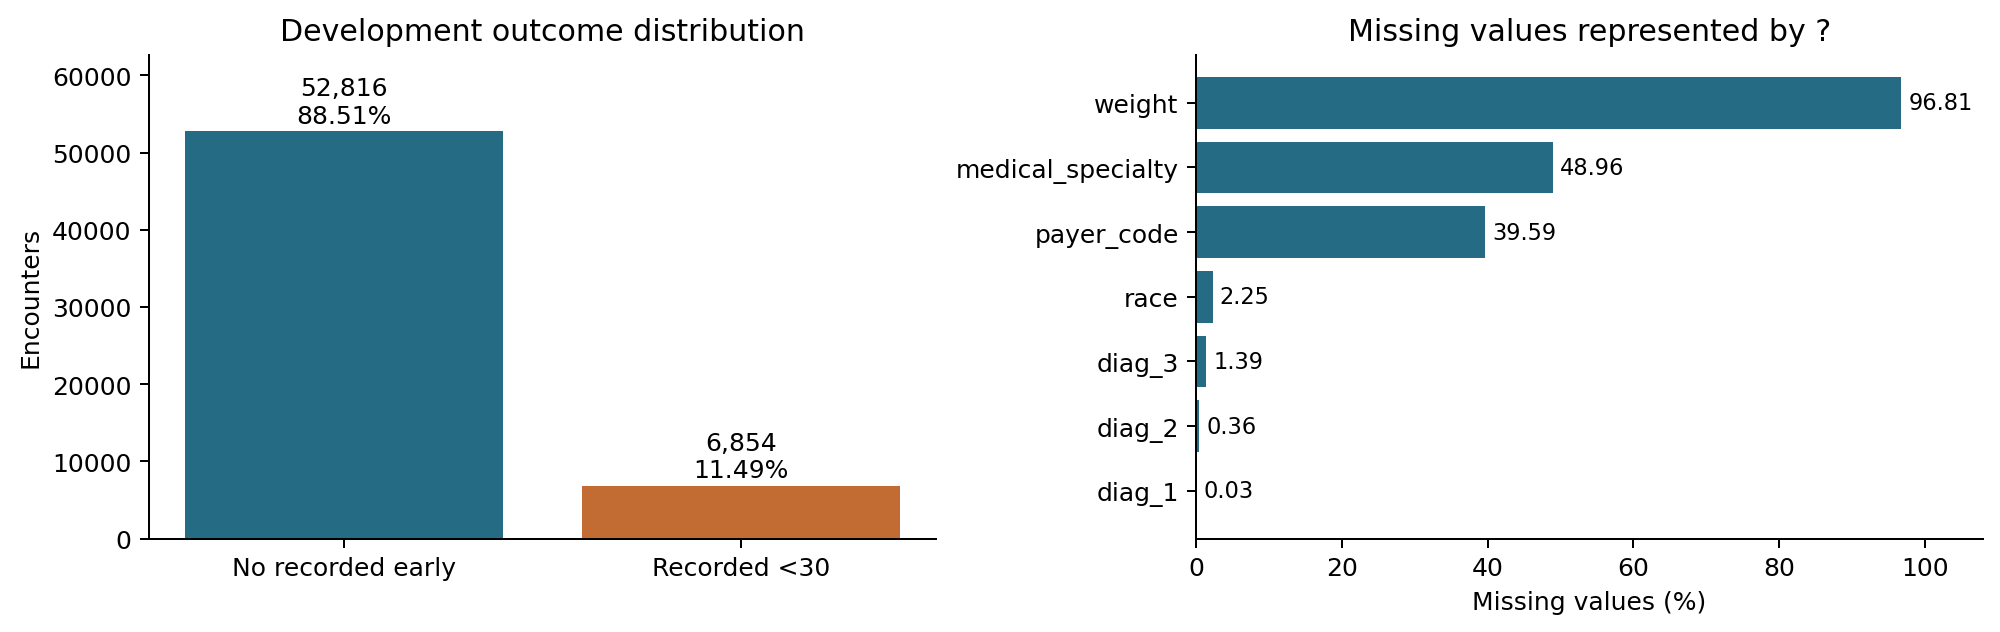

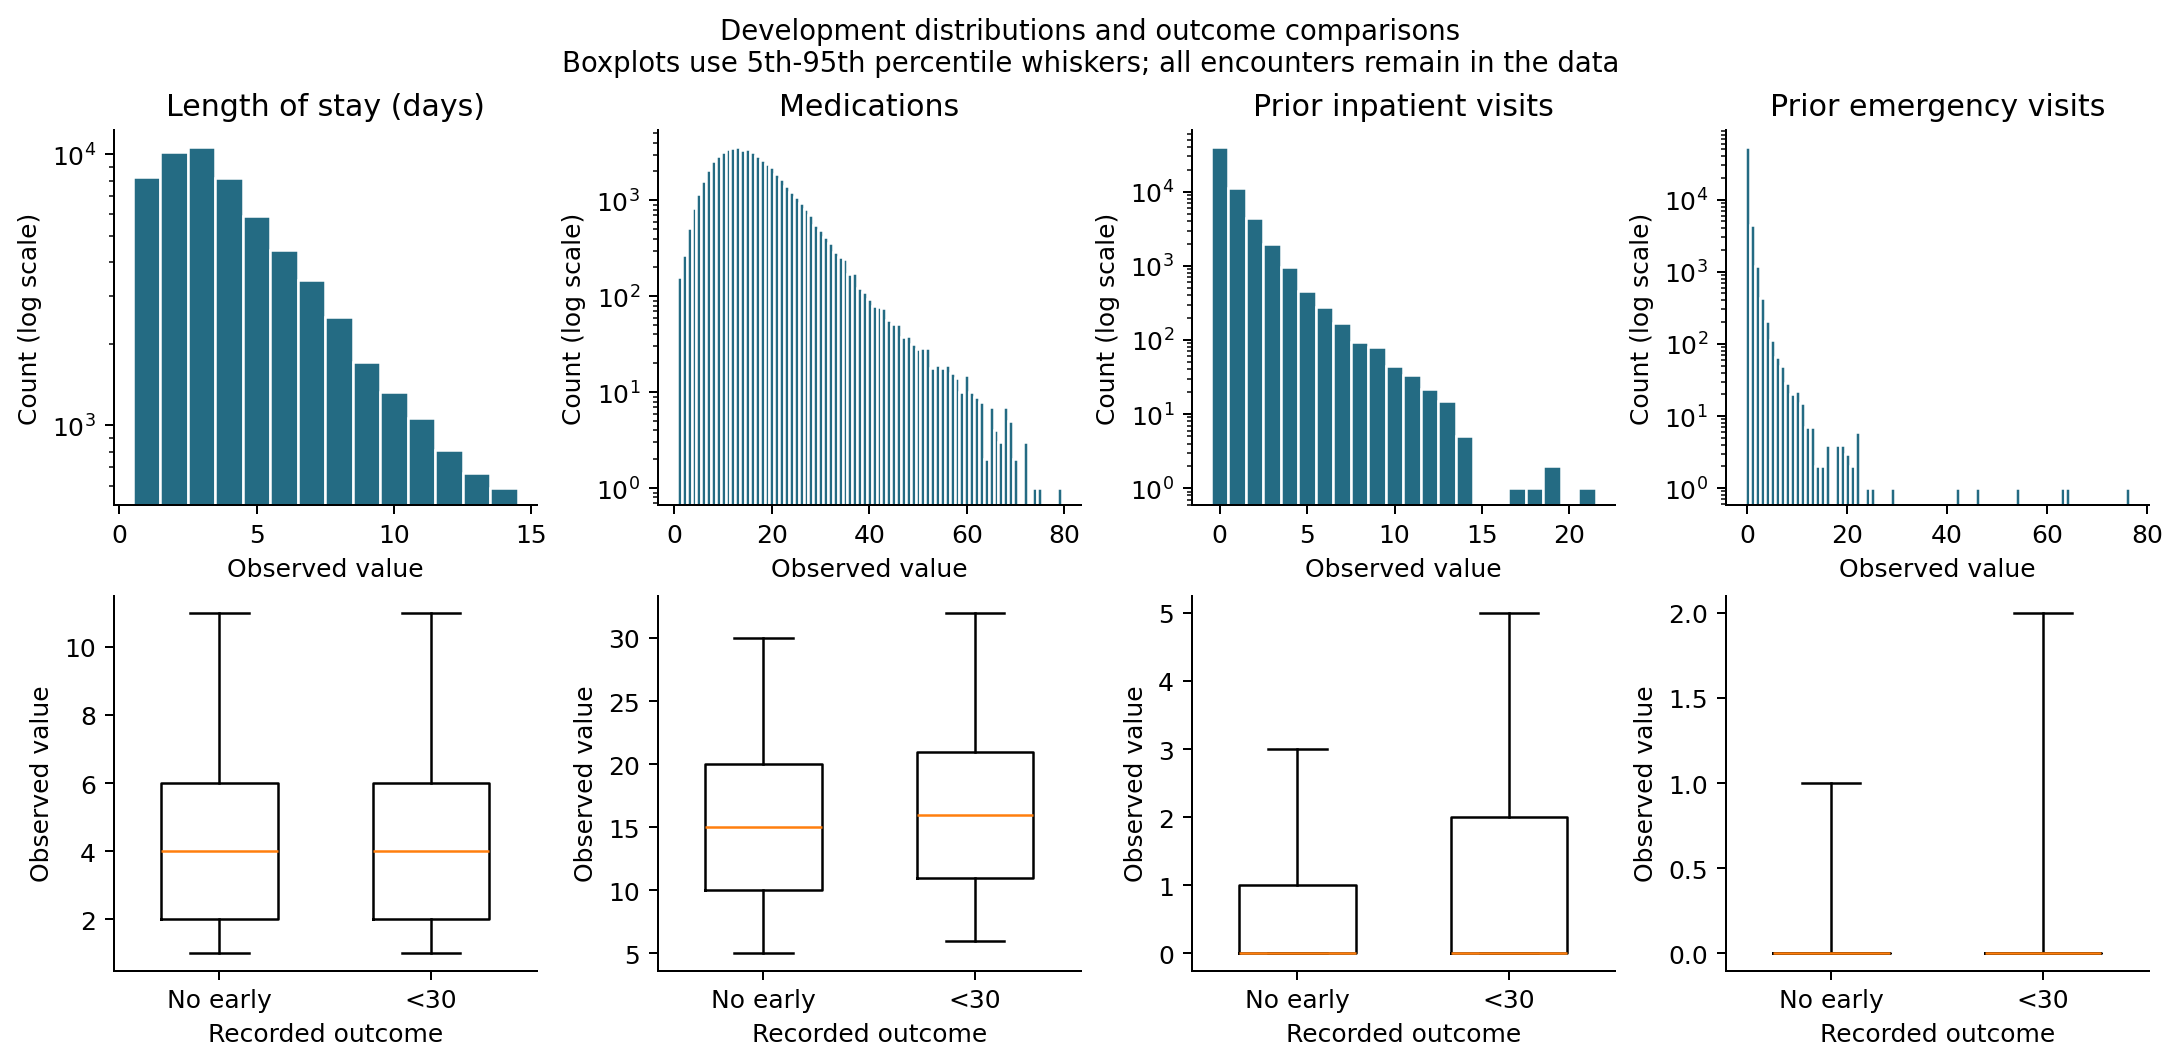

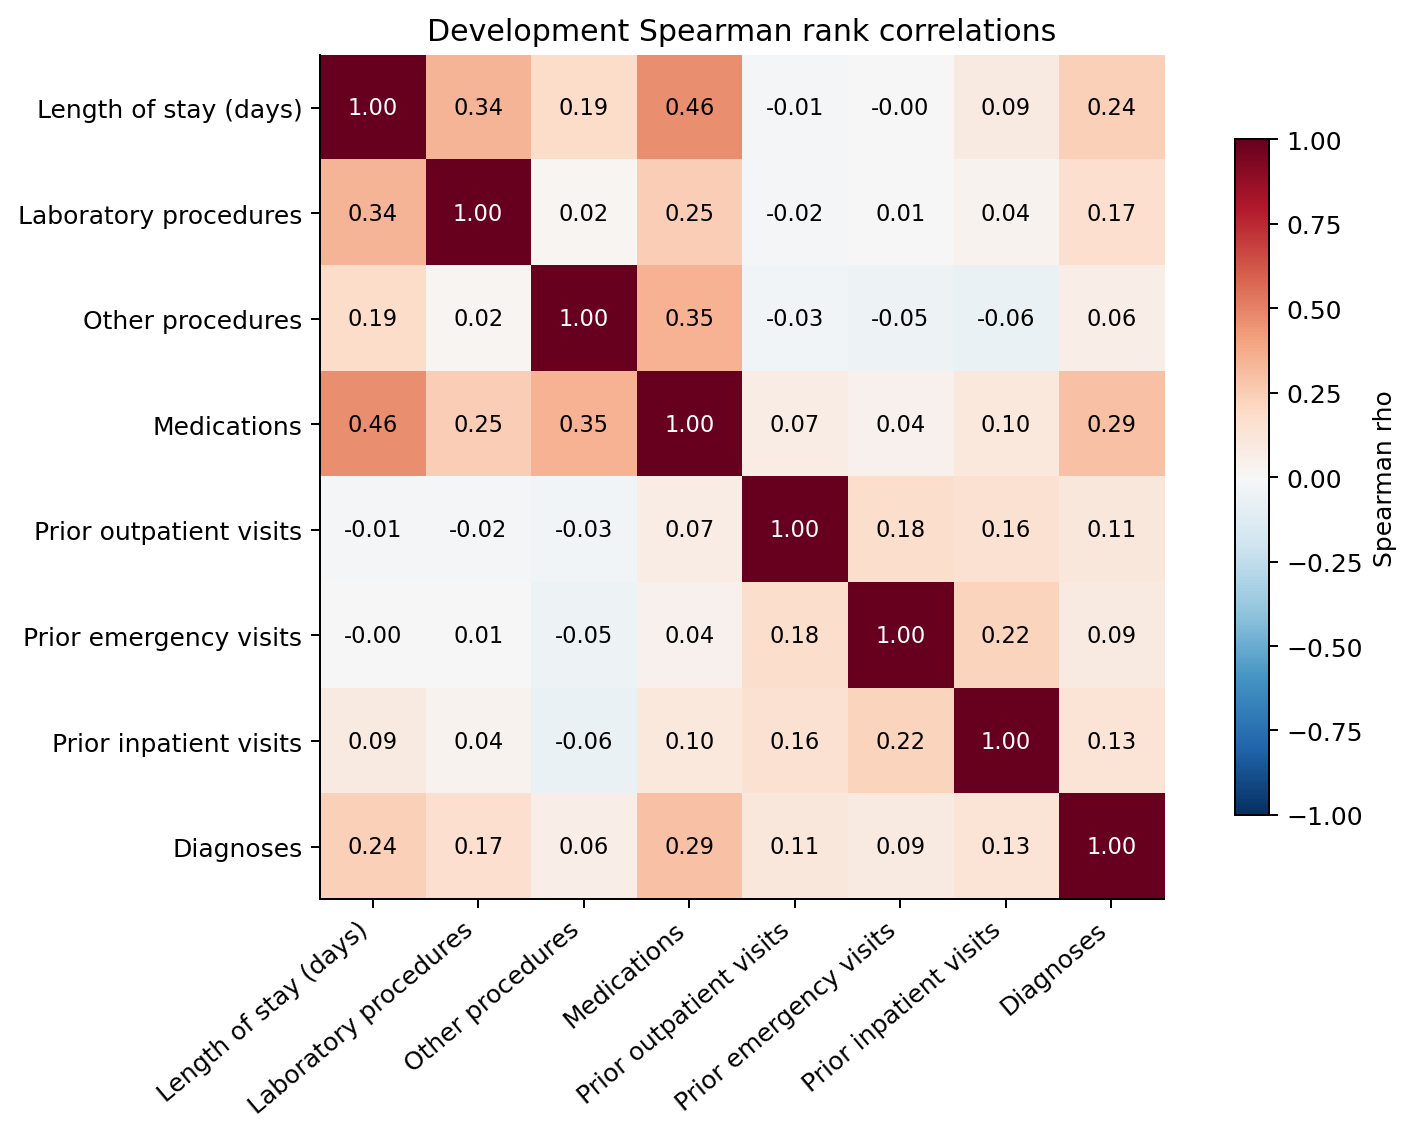

In [8]:
# Four essential multi-panel figures keep the report focused on the supplied rubric.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout='constrained')
counts = y.value_counts().reindex([0, 1])
axes[0].bar(['No recorded early', 'Recorded <30'], counts, color=[BLUE, ORANGE])
for i, count in enumerate(counts):
    axes[0].text(i, count+len(dev)*.018, f'{count:,}\n{count/len(dev):.2%}', ha='center')
axes[0].set(title='Development outcome distribution', ylabel='Encounters', ylim=(0, len(dev)*1.05))
top = missing.loc[missing.missing_count.gt(0)].iloc[::-1]
axes[1].barh(top.feature, top.missing_percent, color=BLUE)
axes[1].set(title='Missing values represented by ?', xlabel='Missing values (%)', xlim=(0, 108))
for i, value in enumerate(top.missing_percent):
    axes[1].text(value+1, i, f'{value:.2f}', va='center', fontsize=9)
save_figure(fig, '01_population_missingness', dpi)

key = ['time_in_hospital', 'num_medications', 'number_inpatient', 'number_emergency']
fig, axes = plt.subplots(2, 4, figsize=(12, 5.8), layout='constrained')
for i, name in enumerate(key):
    axes[0, i].hist(dev[name], bins=np.arange(dev[name].min()-.5, dev[name].max()+1.5), color=BLUE, edgecolor='white')
    axes[0, i].set(title=LABELS[name], ylabel='Count (log scale)', yscale='log', xlabel='Observed value')
    axes[1, i].boxplot([dev.loc[y.eq(0), name], dev.loc[y.eq(1), name]], tick_labels=['No early', '<30'],
                       whis=(5, 95), showfliers=False, widths=.55)
    axes[1, i].set(ylabel='Observed value', xlabel='Recorded outcome')
fig.suptitle('Development distributions and outcome comparisons\nBoxplots use 5th-95th percentile whiskers; all encounters remain in the data', fontsize=11)
save_figure(fig, '02_distributions_boxplots', dpi)

fig, ax = plt.subplots(figsize=(9.2, 6.2), layout='constrained')
im = ax.imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
labels = [LABELS[n] for n in NUMERIC]
ax.set_xticks(range(8), labels, rotation=40, ha='right')
ax.set_yticks(range(8), labels)
for i in range(8):
    for j in range(8):
        value = correlations.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', color='white' if abs(value)>.65 else 'black', fontsize=9)
ax.set_title('Development Spearman rank correlations')
fig.colorbar(im, ax=ax, label='Spearman rho', shrink=.8)
save_figure(fig, '03_correlations', dpi)

**Key EDA findings and challenges.** Early readmission accounts for 11.49% of development encounters, so an always-negative rule would achieve 88.51% accuracy while detecting none. Weight is 96.81% missing; specialty and payer are also frequently missing. Prior utilization is concentrated at zero with long tails. The strongest numeric rank correlation is stay length versus medication count (about 0.463); no pair reaches |rho| ≥ 0.80. This does not rule out nonlinear or categorical redundancy. Outcome boxplots overlap, so one feature does not cleanly separate the classes. Repeated encounters remain dependent within each partition, and the historical US release cannot demonstrate current Canadian hospital performance.

## 5 Training-only cleaning and independent feature selection

The code below defines the complete preprocessing pipeline. Fixed ICD-9 grouping uses no labels. `fit` learns exclusions (>95% missing or constant), median/mean/scale, category vocabularies and MI rankings from development only. Numeric inputs use median imputation then standardization. Categoricals use a `Missing` category and one-hot encoding; levels with fewer than 25 development occurrences are pooled. Lab `None` is preserved. Age bands and integer clinical codes remain categorical.

**Mutual information (MI)** ranks whole cleaned inputs before one-hot encoding, treating counts and categories as discrete. It is a supervised filter independent of classifier fitting. The predeclared top 20 are selected; 20 is a bounded choice, not a demonstrated optimum. MI may favor high-cardinality inputs and miss interactions. IDs, split columns and outcome labels are explicitly rejected as predictors.

In [9]:
def diagnosis_group(value):
    """Fixed ICD-9 group rules; no outcome information is used to construct groups."""
    if pd.isna(value):
        return np.nan
    try:
        code = float(value)
    except (ValueError, TypeError):
        return 'Other'
    if 250 <= code < 251:
        return 'Diabetes'
    for low, high, extra, label in [
        (390, 460, 785, 'Circulatory'), (460, 520, 786, 'Respiratory'),
        (520, 580, 787, 'Digestive'), (580, 630, 788, 'Genitourinary'),
        (710, 740, -1, 'Musculoskeletal'), (800, 1000, -1, 'Injury'),
        (140, 240, -1, 'Neoplasms')]:
        if low <= code < high or int(code) == extra:
            return label
    return 'Other'


class ClinicalCleaner(TransformerMixin, BaseEstimator):
    """Learn high-missingness/constant exclusions from training data, preserving test-not-performed categories."""
    def __init__(self, missing_threshold=0.95):
        self.missing_threshold = missing_threshold

    def _convert(self, X):
        out = X.copy().replace('?', np.nan)
        for col in out:
            if col in NUMERIC:
                out[col] = pd.to_numeric(out[col], errors='raise').astype(float)
            else:
                out[col] = out[col].map(lambda v: str(v) if pd.notna(v) else np.nan)
        for col in ['diag_1', 'diag_2', 'diag_3']:
            if col in out:
                out[col] = out[col].map(diagnosis_group)
        return out

    def fit(self, X, y=None):
        forbidden = {'target', 'readmitted', 'encounter_id', 'patient_nbr', 'split', 'partition_fold'} & set(X.columns)
        if forbidden:
            raise ValueError(f'Identifiers/labels entered preprocessing: {sorted(forbidden)}')
        clean = self._convert(X)
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.columns_ = [c for c in clean if clean[c].isna().mean() <= self.missing_threshold and clean[c].nunique(dropna=False) > 1]
        self.dropped_ = [c for c in clean if c not in self.columns_]
        return self

    def transform(self, X):
        check_is_fitted(self, 'columns_')
        return self._convert(X).loc[:, self.columns_]


class RawMutualInformationSelector(TransformerMixin, BaseEstimator):
    """Rank complete raw inputs, not separate one-hot levels; all current inputs are discrete counts/categories."""
    def __init__(self, k=None, random_state=459):
        self.k = k
        self.random_state = random_state

    def fit(self, X, y):
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        # Integer-valued counts and nominal categories are both discrete here.
        # Factorization is fit locally to the training fold; no encoding is applied to validation data.
        coded = np.column_stack([pd.factorize(X[c], use_na_sentinel=True)[0] for c in X])
        self.scores_ = mutual_info_classif(coded, np.asarray(y), discrete_features=True, random_state=self.random_state)
        order = np.argsort(-self.scores_, kind='stable')
        selected = set(order if self.k is None else order[:min(self.k, len(order))])
        self.columns_ = [c for i, c in enumerate(X.columns) if i in selected]
        return self

    def transform(self, X):
        check_is_fitted(self, 'columns_')
        return X.loc[:, self.columns_]


def encoding():
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=25, dtype=np.float32))])
    return ColumnTransformer([
        ('numeric', numeric, make_column_selector(dtype_include=np.number)),
        ('categorical', categorical, make_column_selector(dtype_exclude=np.number))], sparse_threshold=1.0)

In [10]:
def preprocessing(k=None):
    """A fitted transformer only: cleaning -> independent MI filtering -> imputation/scaling/encoding."""
    return Pipeline([('clean', ClinicalCleaner()),
                     ('select', RawMutualInformationSelector(k=k, random_state=config()['seed'])),
                     ('encode', encoding())])

# These are standalone preprocessing artifacts, not preprocessed inputs for cross-validation.
print('Fitting development-only preprocessing and mutual-information selection...', flush=True)
full = preprocessing().fit(X, y)
selected = preprocessing(settings['selected_features']).fit(X, y)
clean = full.named_steps['clean'].transform(X)
all_matrix = sparse.csr_matrix(full.transform(X), dtype=np.float32)
selected_matrix = sparse.csr_matrix(selected.transform(X), dtype=np.float32)
assert matrix_details(all_matrix)['nonfinite_values'] == 0
assert matrix_details(selected_matrix)['nonfinite_values'] == 0
cleaner, selector = full.named_steps['clean'], selected.named_steps['select']
changes = []
converted = cleaner._convert(X)
for name in X:
    reason = 'retained'
    if name in cleaner.dropped_:
        reason = 'over 95% missing' if converted[name].isna().mean() > .95 else 'constant after diagnosis grouping'
    changes.append({'feature': name, 'retained': name in clean, 'reason': reason,
                    'raw_missing_percent': float(X[name].isna().mean()*100),
                    'distinct_after_grouping_including_missing': int(converted[name].nunique(dropna=False))})
record_table(pd.DataFrame(changes), 'column_decisions')
ranking = pd.DataFrame({'feature': selector.feature_names_in_, 'mutual_information_nats': selector.scores_})
ranking['selected_top20'] = ranking.feature.isin(selector.columns_)
ranking = ranking.sort_values('mutual_information_nats', ascending=False, kind='stable')
ranking.insert(0, 'rank', np.arange(1, len(ranking)+1))
record_table(ranking, 'mutual_information')

enc = full.named_steps['encode']
num_columns = list(enc.transformers_[0][2])
numeric_pipe = enc.named_transformers_['numeric']
scaled_numeric = numeric_pipe.transform(clean[num_columns])
audit = pd.DataFrame({'feature': num_columns, 'missing_before': clean[num_columns].isna().sum().values,
                      'imputation_median': numeric_pipe.named_steps['impute'].statistics_,
                      'training_mean': numeric_pipe.named_steps['scale'].mean_,
                      'training_scale': numeric_pipe.named_steps['scale'].scale_,
                      'mean_after': scaled_numeric.mean(axis=0), 'population_std_after': scaled_numeric.std(axis=0)})
record_table(audit, 'numeric_transform_audit')
cat_columns = list(enc.transformers_[1][2])
cat_encoder = enc.named_transformers_['categorical'].named_steps['onehot']
categorical = []
for name, known, rare in zip(cat_columns, cat_encoder.categories_, cat_encoder.infrequent_categories_):
    rare_count = 0 if rare is None else len(rare)
    categorical.append({'feature': name, 'training_categories_after_imputation': len(known),
                        'pooled_rare_categories': rare_count, 'encoded_columns': len(known)-rare_count+int(rare_count>0)})
record_table(pd.DataFrame(categorical), 'categorical_encoding_audit')
selected_names = selected.named_steps['encode'].get_feature_names_out()
record_table(pd.DataFrame({'matrix_column': np.arange(len(selected_names)), 'encoded_feature': selected_names}), 'encoded_feature_names')
# Matrix row order is explicit, so IDs and labels can never silently drift away from features.
ledger = dev[['encounter_id', 'patient_nbr', 'target']].copy()
ledger.insert(0, 'matrix_row', np.arange(len(dev)))
ledger.to_csv(output('prepared/development_row_index.csv'), index=False)
sparse.save_npz(output('prepared/development_top20.npz'), selected_matrix)
# A compact example connects raw inputs with the numerical operations, without a huge wide preview.
examples = []
for row in range(3):
    for j, name in enumerate(num_columns):
        examples.append({'example_row': row, 'feature': name, 'raw_value': float(X.iloc[row][name]),
                         'imputed_value': float(numeric_pipe.named_steps['impute'].transform(clean[num_columns].iloc[[row]])[0, j]),
                         'standardized_value': float(scaled_numeric[row, j])})
record_table(pd.DataFrame(examples), 'transformation_examples')


display(pd.DataFrame(changes))
display(audit)
display(ranking.head(20))

Fitting development-only preprocessing and mutual-information selection...


,feature,retained,reason,raw_missing_percent,distinct_after_grouping_including_missing
0,race,True,retained,2.252388,6
1,gender,True,retained,0.000000,3
2,age,True,retained,0.000000,10
3,weight,False,over 95% missing,96.807441,10
4,admission_type_id,True,retained,0.000000,8
5,discharge_disposition_id,True,retained,0.000000,21
6,admission_source_id,True,retained,0.000000,16
7,time_in_hospital,True,retained,0.000000,14
8,payer_code,True,retained,39.594436,17
9,medical_specialty,True,retained,48.960952,68


,feature,missing_before,imputation_median,training_mean,training_scale,mean_after,population_std_after
0,time_in_hospital,0,4.0,4.364454,2.952780,1.200314e-16,1.0
1,num_lab_procedures,0,44.0,42.866583,19.568784,1.202695e-16,1.0
2,num_procedures,0,1.0,1.329160,1.702146,9.978797e-17,1.0
3,num_medications,0,15.0,15.968762,8.080749,7.906827e-17,1.0
4,number_outpatient,0,0.0,0.365913,1.251944,4.477360e-17,1.0
5,number_emergency,0,0.0,0.204961,1.031897,-3.572362e-17,1.0
6,number_inpatient,0,0.0,0.637205,1.277424,2.726903e-17,1.0
7,number_diagnoses,0,8.0,7.411111,1.936074,-1.238419e-16,1.0


,rank,feature,mutual_information_nats,selected_top20
14,1,number_inpatient,0.011475,True
4,2,discharge_disposition_id,0.005763,True
13,3,number_emergency,0.002387,True
8,4,medical_specialty,0.001957,True
11,5,num_medications,0.001875,True
6,6,time_in_hospital,0.001663,True
18,7,number_diagnoses,0.001662,True
9,8,num_lab_procedures,0.001379,True
12,9,number_outpatient,0.000982,True
35,10,insulin,0.000820,True


**Transformation results.** Weight and four constant medication fields are removed, leaving 42 raw inputs. All 42 produce 216 encoded columns; MI's 20 inputs produce 147. No numeric values are missing in this development set, so the median imputer changes no current numeric values but supports future missing inputs. Standardization gives training means approximately 0 and population standard deviations 1; it does not remove skewness. Sparse matrix rows match the exported row ledger, and columns match `encoded_feature_names.csv`.

**Leakage boundary:** the exported matrix uses all development labels for MI. Do not use it as preselected input for later cross-validation. Refit the entire pipeline on each training fold from raw features. Calibration/test data remain reserved.

## 6 Outlier handling and augmentation

Screen with 1.5-IQR fences, explicitly identifying zero-IQR features. Complement this with Isolation Forest on log1p-transformed, imputed and standardized numeric inputs (200 trees, fixed 3% flag fraction, seed 459). This log transform belongs to the anomaly screen, not the primary feature matrix. Flags identify unusual observations, not proven errors. Retain all eligible encounters: legitimate high utilization may be relevant to later readmission prediction.

In [11]:
print('Screening outliers without deleting encounters...', flush=True)
fences, iqr_flags = iqr_screen(dev[NUMERIC])
record_table(fences, 'outlier_iqr')
anomaly_scaler = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
anomaly_matrix = anomaly_scaler.fit_transform(np.log1p(dev[NUMERIC]))
detector = IsolationForest(n_estimators=settings['isolation_trees'], contamination=settings['outlier_flag_fraction'],
                           random_state=seed, n_jobs=config()['threads']).fit(anomaly_matrix)
isolated = detector.predict(anomaly_matrix) == -1
outlier_rows = ledger[['matrix_row', 'encounter_id']].copy()
outlier_rows['iqr_any_flag'] = iqr_flags.any(axis=1)
outlier_rows['isolation_forest_flag'] = isolated
# Keep per-row flags in memory; the profile and fence tables are displayed below.
profile = dev[NUMERIC].assign(flagged=isolated).groupby('flagged').median().reset_index()
profile.insert(1, 'encounters', [int((isolated == flag).sum()) for flag in profile.flagged])
record_table(profile, 'outlier_profiles')


display(fences)
display(profile)

Screening outliers without deleting encounters...


,feature,q1,q3,iqr,lower_fence,upper_fence,zero_iqr,flagged_encounters,flagged_percent
0,time_in_hospital,2.0,6.0,4.0,-4.0,12.0,False,1256,2.104910
1,num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,False,74,0.124015
2,num_procedures,0.0,2.0,2.0,-3.0,5.0,False,2894,4.850008
3,num_medications,10.0,20.0,10.0,-5.0,35.0,False,1452,2.433384
4,number_outpatient,0.0,0.0,0.0,0.0,0.0,True,9772,16.376739
5,number_emergency,0.0,0.0,0.0,0.0,0.0,True,6709,11.243506
6,number_inpatient,0.0,1.0,1.0,-1.5,2.5,False,4140,6.938160
7,number_diagnoses,6.0,9.0,3.0,1.5,13.5,False,159,0.266466


,flagged,encounters,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
0,False,57879,4.0,44.0,1.0,15.0,0.0,0.0,0.0,8.0
1,True,1791,3.0,35.0,1.0,15.0,1.0,2.0,2.0,8.0


**Interpretation:** 20,162 development encounters trigger at least one IQR flag, while Isolation Forest flags 1,791 (3%). Outpatient and emergency counts have zero IQR, so any positive count triggers their IQR screen. Flagged Isolation Forest records have median prior emergency/inpatient counts of two, versus zero in the unflagged group. No outlier rows are deleted and no augmentation, oversampling or synthetic records are used. Preserving prevalence keeps the EDA descriptive. Any future resampling must occur inside training folds; interpolating categorical clinical records may create invalid combinations.

## 7 PCA for the encoded dimensionality

One-hot encoding expands the representation to 216 columns. Centered PCA with full SVD retains at least 95% of variance, using standardized numerical inputs and binary categorical indicators (indicators are not separately variance-scaled). PCA does not use labels. It is a separate diagnostic representation; it does not establish predictive improvement or replace the proposal's later classifier comparisons. Variance/loadings/centering tables remain in the notebook as `evidence_tables`; all score rows are available in memory as `scores` on each run.

Fitting centered PCA on all development-encoded inputs...


,component,variance_ratio,cumulative_variance_ratio
60,61,0.002246,0.942699
61,62,0.002226,0.944925
62,63,0.002143,0.947068
63,64,0.002040,0.949108
64,65,0.001986,0.951094


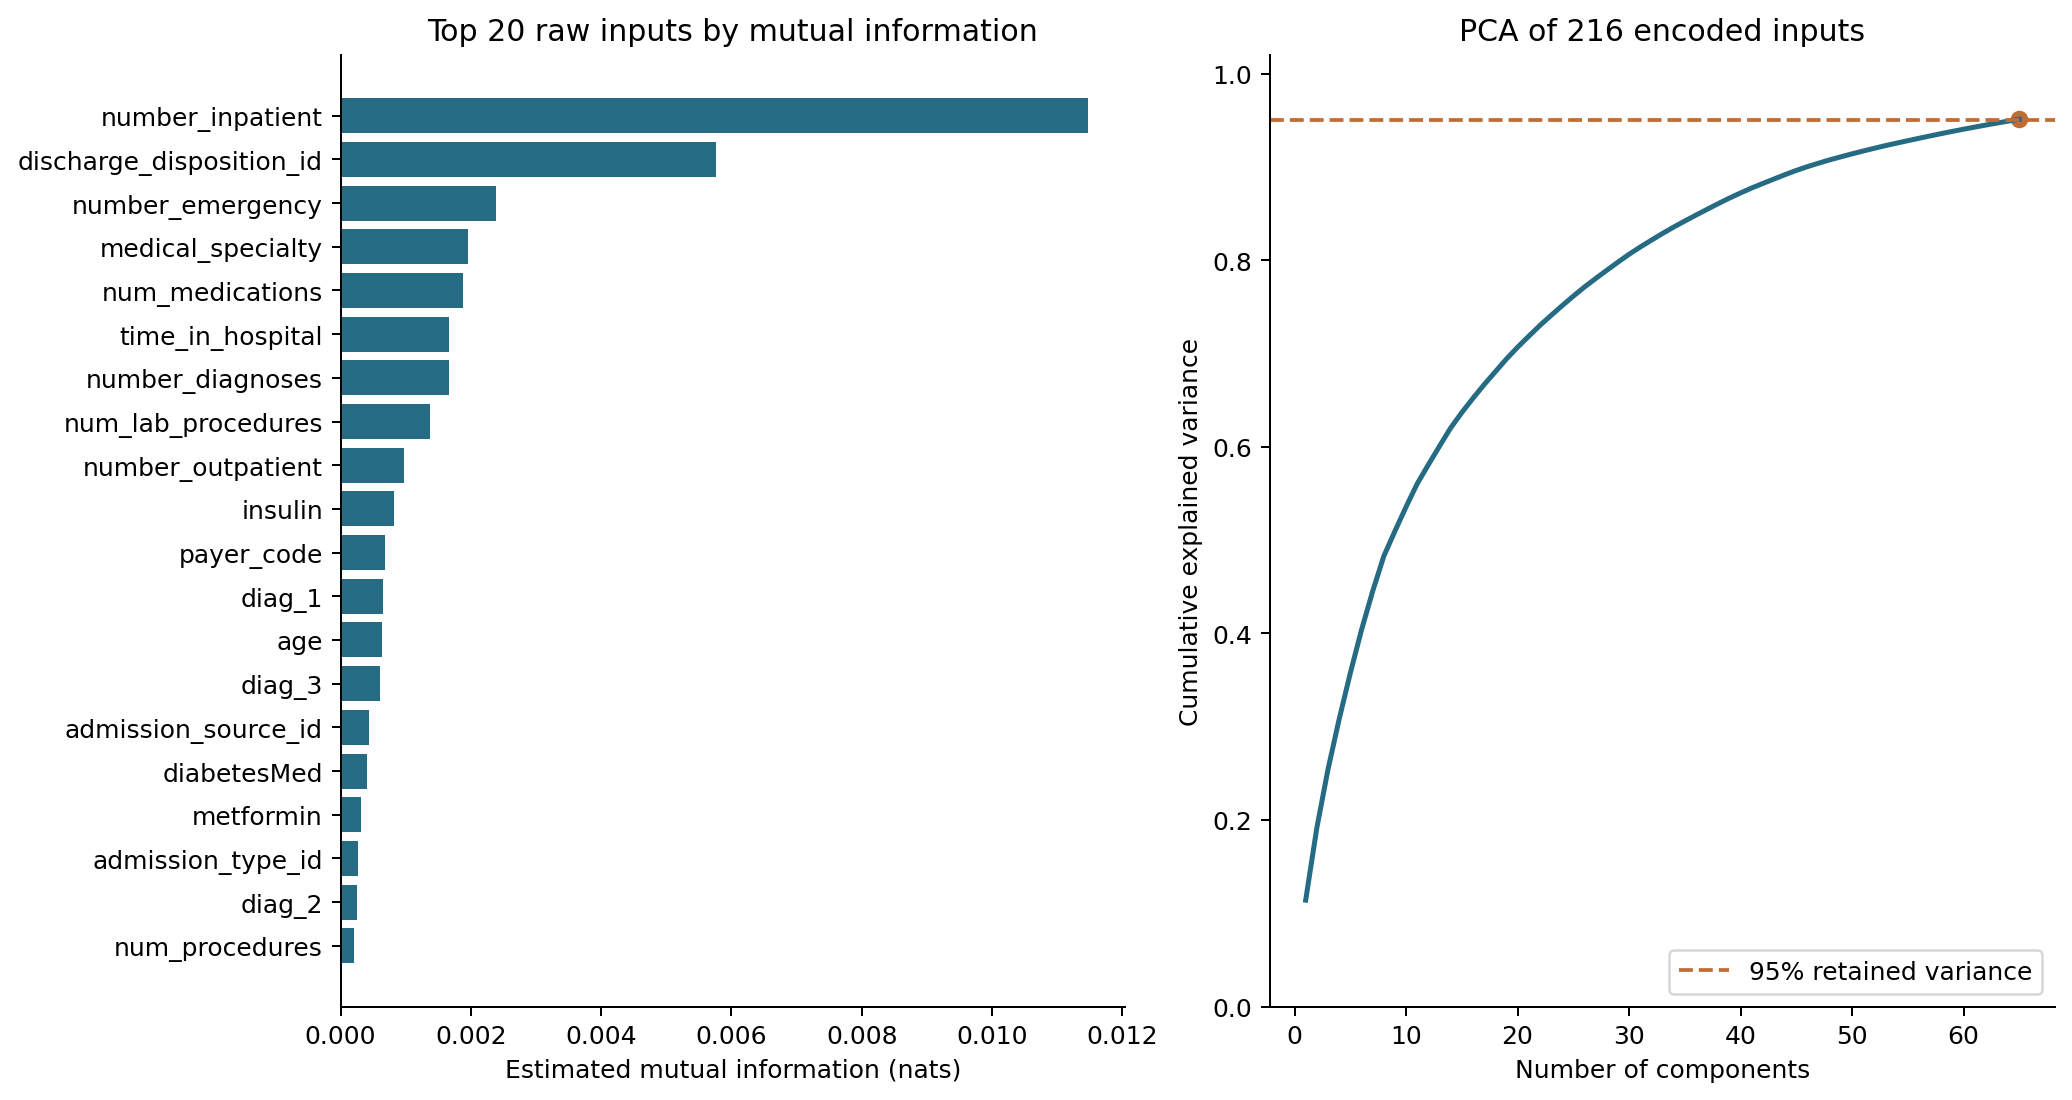

In [12]:
# PCA addresses the actual encoded dimensionality, rather than applying only to 8 numeric inputs.
print('Fitting centered PCA on all development-encoded inputs...', flush=True)
dense = all_matrix.toarray().astype(np.float64)
pca = PCA(n_components=settings['pca_retained_variance'], svd_solver='full')
scores = pca.fit_transform(dense)

# Check that the fitted model reproduces its scores before saving
np.testing.assert_allclose(
    pca.transform(dense), scores, atol=1e-7, rtol=1e-7
)
explained = pd.DataFrame({'component': np.arange(1, len(pca.explained_variance_ratio_)+1),
                          'variance_ratio': pca.explained_variance_ratio_,
                          'cumulative_variance_ratio': np.cumsum(pca.explained_variance_ratio_)})
record_table(explained, 'pca_variance')
names = full.named_steps['encode'].get_feature_names_out()
record_table(pd.DataFrame(pca.components_[:2].T, index=names, columns=['PC1_loading', 'PC2_loading']).rename_axis('encoded_feature').reset_index(), 'pca_loadings')
del dense


# Store compact evidence for all retained components, not a large duplicate score matrix.
record_table(pd.DataFrame(pca.components_.T, index=names,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]).rename_axis('encoded_feature').reset_index(), 'pca_components')
record_table(pd.DataFrame({'encoded_feature': names, 'centering_mean': pca.mean_}), 'pca_centering')
display(explained.tail())

fig, axes = plt.subplots(1, 2, figsize=(11.4, 6), layout='constrained')
displayed = ranking.head(settings['selected_features']).iloc[::-1]
axes[0].barh(displayed.feature, displayed.mutual_information_nats, color=BLUE)
axes[0].set(title='Top 20 raw inputs by mutual information', xlabel='Estimated mutual information (nats)')
axes[1].plot(explained.component, explained.cumulative_variance_ratio, color=BLUE, linewidth=2)
axes[1].axhline(settings['pca_retained_variance'], color=ORANGE, ls='--', label='95% retained variance')
axes[1].scatter([pca.n_components_], [explained.cumulative_variance_ratio.iloc[-1]], color=ORANGE)
axes[1].set(title=f'PCA of {all_matrix.shape[1]} encoded inputs', xlabel='Number of components',
             ylabel='Cumulative explained variance', ylim=(0, 1.02))
axes[1].legend(loc='lower right')
save_figure(fig, '04_selection_pca', dpi)

**Selection and PCA results:** inpatient visits, discharge disposition and emergency visits lead the MI ranking. PCA retains 65 components explaining 95.11% of variance; the first two explain only 19.15%, so a 2D projection loses most variation. PCA mixes original variables and reduces direct interpretation. Explained variance is not predictive accuracy. All retained component weights and centering means remain in `evidence_tables` for inspection.

In [13]:
summary = {'scope': 'Section 3 only; development EDA and preprocessing; no classifier results',
           'data': data_audit, 'development_encounters': len(dev),
           'development_patients': int(dev.patient_nbr.nunique()), 'development_positives': int(y.sum()),
           'development_positive_rate': float(y.mean()), 'numeric_inputs': len(NUMERIC),
           'categorical_candidate_inputs': int(len(X.columns)-len(NUMERIC)),
           'retained_raw_inputs': len(clean.columns), 'selected_raw_inputs': len(selector.columns_),
           'dropped_columns': cleaner.dropped_, 'all_encoded': matrix_details(all_matrix),
           'selected_encoded': matrix_details(selected_matrix),
           'pca_components': int(pca.n_components_), 'pca_retained_variance': float(pca.explained_variance_ratio_.sum()),
           'pca_first_two_variance': float(pca.explained_variance_ratio_[:2].sum()),
           'strongest_numeric_correlation': pairs.iloc[0].drop('absolute_rho').to_dict(),
           'pairs_with_abs_rho_at_least_0_8': int(pairs.absolute_rho.ge(settings['strong_correlation_threshold']).sum()),
           'iqr_any_flagged': int(iqr_flags.any(axis=1).sum()), 'isolation_flagged': int(isolated.sum()),
           'outlier_rows_removed': 0, 'synthetic_rows_added': 0,
           'numeric_missing_cells': int(X[NUMERIC].isna().sum().sum()),
           'duplicate_encounter_ids': int(raw.encounter_id.duplicated().sum()),
           'settings': settings, 'environment': environment(), 'elapsed_seconds': perf_counter()-start,
           'fit_scope': 'Every learned transformation in this section fits development only. Refit inside each training fold for later CV.',
           'pca_scope': 'Centered numeric-standardized and binary-one-hot representation; labels are not inputs to PCA. Separate diagnostic alternative, not a change to the proposal classifier pipeline.',
           'outlier_scope': 'IQR screening plus one IsolationForest on the full development set. Flags identify unusual records, not confirmed errors. No labels enter the detector.',
           'augmentation_scope': 'None. Original class prevalence is retained. Oversampling before splitting would risk leakage; SMOTE is not required by this section.'}
record_audit('summary.json', summary)

display(pd.Series({k: summary[k] for k in ['development_encounters', 'development_positive_rate', 'retained_raw_inputs', 'selected_raw_inputs', 'pca_components', 'pca_retained_variance', 'outlier_rows_removed', 'synthetic_rows_added']}, name='Measured result').to_frame())

,Measured result
development_encounters,59670.000000
development_positive_rate,0.114865
retained_raw_inputs,42.000000
selected_raw_inputs,20.000000
pca_components,65.000000
pca_retained_variance,0.951094
outlier_rows_removed,0.000000
synthetic_rows_added,0.000000


## 8 Verify the preprocessing and exported evidence

Six checks cover training-only learning on synthetic train/validation data, MI before one-hot encoding, zero-IQR behavior, exported matrix row alignment/reproduction, PCA score reproduction and the real-data audits. A failed assertion stops execution. These checks validate code behavior and data integrity; they do not validate clinical usefulness.

In [14]:
def test_median_and_scaler_learn_training_values_only():
    X = pd.DataFrame({'time_in_hospital': [1., 2., np.nan, 5.], 'age': ['young', 'old', 'young', 'old']})
    model = preprocessing().fit(X, np.array([0, 1, 0, 1]))
    numeric = model.named_steps['encode'].named_transformers_['numeric']
    np.testing.assert_allclose(numeric.named_steps['impute'].statistics_, [2.])
    np.testing.assert_allclose(numeric.named_steps['scale'].mean_, [2.5])
    before = numeric.named_steps['scale'].mean_.copy()
    validation = pd.DataFrame({'time_in_hospital': [1000., np.nan], 'age': ['new', 'old']})
    encoded = model.transform(validation)
    np.testing.assert_array_equal(before, numeric.named_steps['scale'].mean_)
    assert encoded.shape[0] == 2
    assert np.isfinite(encoded.toarray() if sparse.issparse(encoded) else encoded).all()


def test_mutual_information_selects_whole_input_before_onehot():
    y = np.tile([0, 1], 100)
    X = pd.DataFrame({'age': np.where(y, 'older', 'younger'), 'time_in_hospital': np.tile([1, 1, 2, 2], 50)})
    model = preprocessing(k=1).fit(X, y)
    assert model.named_steps['select'].columns_ == ['age']
    assert model.transform(X).shape == (200, 2)


def test_zero_iqr_flags_are_not_automatic_deletions():
    values = pd.DataFrame({'number_emergency': [0]*98+[1, 20]})
    original = values.copy()
    summary, flags = iqr_screen(values)
    assert summary.iloc[0].zero_iqr
    assert flags.number_emergency.sum() == 2
    pd.testing.assert_frame_equal(values, original)


def test_exported_matrix_preserves_rows_and_reproduces_transform():
    dev = load_cohort('development')
    X, _ = xy(dev)
    matrix = sparse.load_npz(OUT/'prepared/development_top20.npz')
    ledger = pd.read_csv(OUT/'prepared/development_row_index.csv')
    model = selected
    assert matrix.shape[0] == len(ledger) == len(dev)
    np.testing.assert_array_equal(ledger.encounter_id, dev.encounter_id)
    np.testing.assert_array_equal(ledger.target, dev.target)
    np.testing.assert_allclose(model.transform(X.iloc[:128]).toarray(), matrix[:128].toarray(), atol=1e-6, rtol=1e-6)
    assert np.isfinite(matrix.data).all()


def test_pca_export_reproduces_and_meets_variance_rule():
    X, _ = xy(load_cohort('development').iloc[:128])
    model = full
    matrix = sparse.csr_matrix(model.transform(X), dtype=np.float32).toarray()
    saved = scores[:128]
    np.testing.assert_allclose(pca.transform(matrix), saved, atol=1e-4, rtol=1e-4)
    assert pca.explained_variance_ratio_.sum() >= .95
    assert pca.explained_variance_ratio_[:-1].sum() < .95


def test_audits_match_development_and_no_outliers_are_removed():
    dev = load_cohort('development')
    X, _ = xy(dev)
    decisions = evidence_tables['column_decisions']
    numeric = evidence_tables['numeric_transform_audit']
    flags = outlier_rows
    assert len(decisions) == 47 and decisions.retained.sum() == 42
    assert len(flags) == len(dev)
    np.testing.assert_allclose(numeric.mean_after, 0, atol=1e-12)
    np.testing.assert_allclose(numeric.population_std_after, 1, atol=1e-12)
    assert numeric.missing_before.sum() == X[NUMERIC].isna().sum().sum() == 0
    assert X['A1Cresult'].eq('None').any()

checks = [test_median_and_scaler_learn_training_values_only,
          test_mutual_information_selects_whole_input_before_onehot,
          test_zero_iqr_flags_are_not_automatic_deletions,
          test_exported_matrix_preserves_rows_and_reproduces_transform,
          test_pca_export_reproduces_and_meets_variance_rule,
          test_audits_match_development_and_no_outliers_are_removed]
passed = []
for check in checks:
    check()
    passed.append(check.__name__)
    print('PASS', check.__name__)
record_audit('verification.json', {'passed': len(passed), 'failed': 0, 'checks': passed,
                               'raw_sha256': source_hash, 'patient_overlap': 0})
print('Finished. All analysis, figures and prepared data were regenerated from local input.')

PASS test_median_and_scaler_learn_training_values_only
PASS test_mutual_information_selects_whole_input_before_onehot
PASS test_zero_iqr_flags_are_not_automatic_deletions


PASS test_exported_matrix_preserves_rows_and_reproduces_transform
PASS test_pca_export_reproduces_and_meets_variance_rule


PASS test_audits_match_development_and_no_outliers_are_removed
Finished. All analysis, figures and prepared data were regenerated from local input.


## 9 Reporting notes and sources

Use the four essential PNGs in `outputs/figures/` and the measured tables to support your own report. Discuss the dataset/target, quality findings, exclusion rules, preprocessing methods, MI, PCA, outliers, augmentation and limitations. Explain what changed in the observed data versus precautions present in the code. The annotated report is included as `Report.pdf`. Review and finalize it with your team. The key results and method explanations are included in this notebook.

- UCI dataset and license: https://doi.org/10.24432/C5230J and https://creativecommons.org/licenses/by/4.0/
- MI implementation: https://scikit-learn.org/1.7/modules/generated/sklearn.feature_selection.mutual_info_classif.html
- PCA: https://scikit-learn.org/1.7/modules/generated/sklearn.decomposition.PCA.html
- Isolation Forest: https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.IsolationForest.html

Historical data, incomplete readmission capture, missing hospital/date fields, selective testing and correlated repeated encounters limit interpretation. No causal effect, external validation or current clinical performance is claimed.